In [21]:
# ============================================================
# 1. Import Libraries
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense, Dropout,
    Layer, Input
)
from tensorflow.keras.models import Model

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [22]:
# ============================================================
# 2. Load Dataset
# ============================================================

df = pd.read_csv("/content/Tweets.csv")

print(df.head())
print(df.columns)
print("Dataset shape:", df.shape)

# Keep required columns
df = df[['text', 'airline_sentiment']].dropna()

# Remove empty tweets
df['text'] = df['text'].astype(str).str.strip()
df = df[df['text'] != '']

print("\nSentiment distribution:")
print(df['airline_sentiment'].value_counts())

             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
0                    NaN     cairdin                 NaN              0   
1                    NaN    jnar

In [23]:
# ============================================================
# 3. One-Hot Encode Sentiment Labels
# ============================================================

# Fixed order for consistent class interpretation
class_names = ['negative', 'neutral', 'positive']

df = df[df['airline_sentiment'].isin(class_names)].copy()

labels = pd.get_dummies(
    pd.Categorical(
        df['airline_sentiment'],
        categories=class_names
    )
).astype(int)

y = labels.to_numpy()

print("\nOne-hot encoded labels:")
print(labels.head())
print("Y shape:", y.shape)


One-hot encoded labels:
   negative  neutral  positive
0         0        1         0
1         0        0         1
2         0        1         0
3         1        0         0
4         1        0         0
Y shape: (14640, 3)


In [24]:
# ============================================================
# 4. Text Preprocessing
# ============================================================

X = df['text'].to_numpy()

vocab_size = 500
max_length = 50

X_encoded = [
    one_hot(sentence, vocab_size)
    for sentence in X
]

X_padded = pad_sequences(
    X_encoded,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("\nX shape:", X_padded.shape)
print("Y shape:", y.shape)


X shape: (14640, 50)
Y shape: (14640, 3)


In [25]:
# ============================================================
# 5. Train-Validation-Test Split: 60:20:20
# ============================================================

# First split: 80% temporary, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X_padded,
    y,
    test_size=0.20,
    random_state=42,
    stratify=np.argmax(y, axis=1)
)

# Second split: 60% train, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    random_state=42,
    stratify=np.argmax(y_temp, axis=1)
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


Training samples: 8784
Validation samples: 2928
Testing samples: 2928


In [26]:
# ============================================================
# 6. Define Attention Layer
# ============================================================

class AttentionLayer(Layer):

    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):

        # Learnable attention weight vector
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )

        self.b = self.add_weight(
            name="attention_bias",
            shape=(1,),
            initializer="zeros",
            trainable=True
        )

        super(AttentionLayer, self).build(input_shape)

    def call(self, inputs):

        # inputs shape: (batch_size, max_length, hidden_units)

        # Calculate attention scores for each time step
        scores = tf.tanh(
            tf.matmul(inputs, self.W) + self.b
        )

        # Shape: (batch_size, max_length)
        scores = tf.squeeze(scores, axis=-1)

        # Convert scores into attention weights
        attention_weights = tf.nn.softmax(scores, axis=1)

        # Shape: (batch_size, max_length, 1)
        attention_weights = tf.expand_dims(
            attention_weights, axis=-1
        )

        # Weighted sum of LSTM outputs
        context_vector = tf.reduce_sum(
            inputs * attention_weights,
            axis=1
        )

        # Shape: (batch_size, hidden_units)
        return context_vector

In [27]:
# ============================================================
# 7. Build LSTM + Attention Model
# ============================================================

embedding_dim = 128

inputs = Input(shape=(max_length,), name="tweet_input")

# Convert word IDs into dense vectors
embedding = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    name="embedding"
)(inputs)

# Return output for every time step
lstm_output = LSTM(
    128,
    return_sequences=True,
    name="lstm"
)(embedding)

# Apply attention
context_vector = AttentionLayer(name="attention")(lstm_output)

# Classification layers
x = Dropout(0.5)(context_vector)
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)

outputs = Dense(
    3,
    activation='softmax',
    name="sentiment_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="LSTM_Attention_Sentiment"
)

model.summary()

Model: "LSTM_Attention_Sentiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tweet_input (InputLayer)        │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 50, 128)        │        64,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50, 128)        │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (AttentionLayer)      │ (None, 128)            │           129 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sentiment_output (Dense)        │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 204,164 (797.52 KB)

 Trainable params: 204,164 (797.52 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# ============================================================
# 8. Compile Model
# ============================================================

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [29]:
# ============================================================
# 9. Train Model
# ============================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.6470 - loss: 0.8523 - val_accuracy: 0.7005 - val_loss: 0.7155
Epoch 2/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7005 - loss: 0.7111 - val_accuracy: 0.7046 - val_loss: 0.6896
Epoch 3/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7277 - loss: 0.6696 - val_accuracy: 0.7357 - val_loss: 0.6758
Epoch 4/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7511 - loss: 0.6292 - val_accuracy: 0.7285 - val_loss: 0.6423
Epoch 5/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7643 - loss: 0.5968 - val_accuracy: 0.7278 - val_loss: 0.6498
Epoch 6/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7691 - loss: 0.5801 - val_accuracy: 0.7336 - val_loss: 0.6450
Epoch 7/20
138/138 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7683 - loss: 0.5743 - val_accuracy: 0.7339 - val_loss: 0.6425


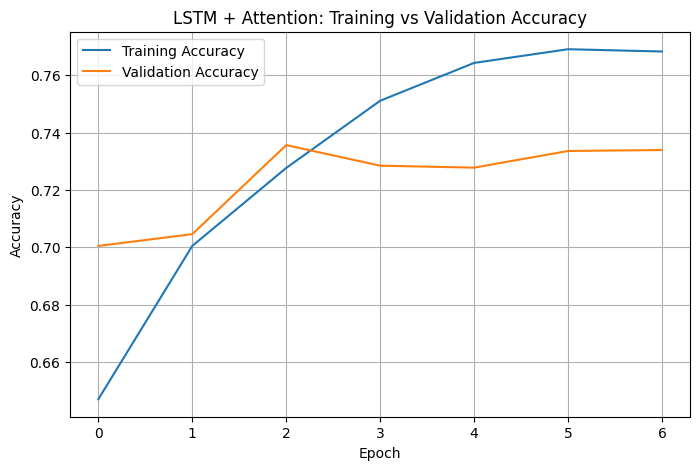

In [30]:
# ============================================================
# 10. Plot Training and Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)
plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('LSTM + Attention: Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

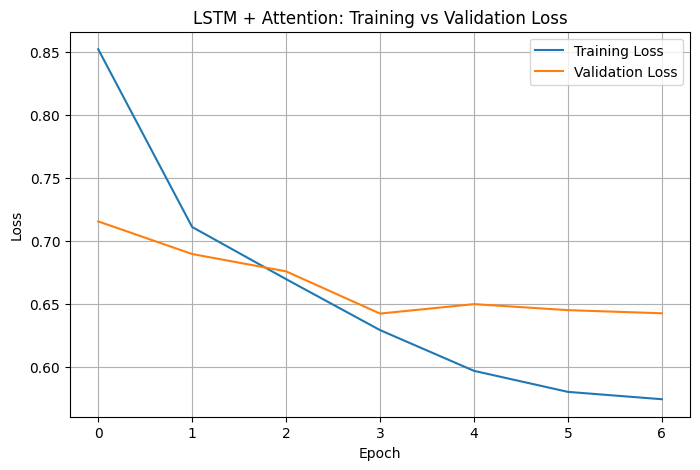

In [31]:
# ============================================================
# 11. Plot Training and Validation Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)
plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('LSTM + Attention: Training vs Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

In [32]:
# ============================================================
# 12. Evaluate Model
# ============================================================

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


Test Loss: 0.6376740336418152
Test Accuracy: 0.748633861541748


In [33]:
# ============================================================
# 13. Predictions
# ============================================================

y_pred_prob = model.predict(X_test, verbose=0)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print("\nPredicted:", y_pred[:10])
print("Actual   :", y_true[:10])

print(
    "\nAccuracy Score:",
    accuracy_score(y_true, y_pred)
)


Predicted: [1 1 0 0 0 0 0 0 0 1]
Actual   : [1 2 0 0 0 0 1 0 0 0]

Accuracy Score: 0.7486338797814208


In [34]:
# ============================================================
# 14. Classification Report
# ============================================================

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    negative       0.81      0.88      0.84      1835
     neutral       0.57      0.56      0.57       620
    positive       0.69      0.49      0.57       473

    accuracy                           0.75      2928
   macro avg       0.69      0.64      0.66      2928
weighted avg       0.74      0.75      0.74      2928



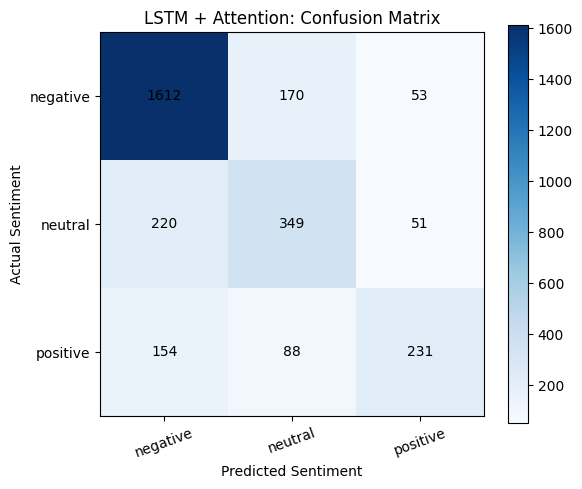

In [35]:
# ============================================================
# 15. Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')

plt.title('LSTM + Attention: Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.xticks(range(3), class_names, rotation=20)
plt.yticks(range(3), class_names)

plt.colorbar()

for i in range(3):
    for j in range(3):
        plt.text(
            j, i, str(cm[i, j]),
            ha='center',
            va='center'
        )

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# 16. Predict New Tweet
# ============================================================

tweet = "The flight was amazing and the staff were very helpful"

tweet_encoded = one_hot(tweet, vocab_size)

tweet_padded = pad_sequences(
    [tweet_encoded],
    maxlen=max_length,
    padding='post',
    truncating='post'
)

prediction = model.predict(tweet_padded, verbose=0)

predicted_class = np.argmax(prediction[0])

print("\nNew Tweet:", tweet)
print("Prediction probabilities:")

for i, sentiment in enumerate(class_names):
    print(f"{sentiment}: {prediction[0][i]:.4f}")

print("Predicted Sentiment:", class_names[predicted_class])


New Tweet: The flight was amazing and the staff were very helpful
Prediction probabilities:
negative: 0.1588
neutral: 0.1296
positive: 0.7115
Predicted Sentiment: positive


In [37]:
# ============================================================
# 17. Save Trained Model
# ============================================================

# Save complete model architecture, weights and optimizer state
model.save("/content/LSTM_Attention_Sentiment.keras")

print("Model saved successfully!")

Model saved successfully!


In [38]:
import tensorflow as tf

loaded_model = tf.keras.models.load_model(
    "/content/LSTM_Attention_Sentiment.keras",
    custom_objects={
        "AttentionLayer": AttentionLayer
    }
)

print("Model loaded successfully!")

Model loaded successfully!


In [39]:
# ============================================================
# 19. Evaluate Saved Model on Test Data
# ============================================================

test_loss, test_accuracy = loaded_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\n========== SAVED MODEL RESULTS ==========")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7486 - loss: 0.6377

========== SAVED MODEL RESULTS ==========
Test Loss: 0.6376740336418152
Test Accuracy: 0.748633861541748


In [40]:
test_loss, test_accuracy = loaded_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7486 - loss: 0.6377

Test Loss: 0.6376740336418152
Test Accuracy: 0.748633861541748


In [41]:
y_pred_prob = loaded_model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

print("Predicted:", y_pred[:10])
print("Actual   :", y_true[:10])

92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Predicted: [1 1 0 0 0 0 0 0 0 1]
Actual   : [1 2 0 0 0 0 1 0 0 0]


In [42]:
from sklearn.metrics import classification_report, accuracy_score

print("Accuracy:", accuracy_score(y_true, y_pred))

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

Accuracy: 0.7486338797814208
              precision    recall  f1-score   support

    negative       0.81      0.88      0.84      1835
     neutral       0.57      0.56      0.57       620
    positive       0.69      0.49      0.57       473

    accuracy                           0.75      2928
   macro avg       0.69      0.64      0.66      2928
weighted avg       0.74      0.75      0.74      2928

